# Problem Set 6 - Clustering Algorithm


Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
Download a clustering dataset from UCI Machine Learning Repository. 

Then explore the dataset using the code implementation of K-Means Clustering Algorithm and evaluate your clustering model using Elbow Method explained in the link:  

- https://www.datacamp.com/tutorial/k-means-clustering-python
- https://medium.com/mlearning-ai/k-means-clustering-with-scikit-learn-e2af706450e4
- https://www.analyticsvidhya.com/blog/2021/04/k-means-clustering-simplified-in-python/

Write a report containing two (2) sections describing the Dataset and the Result. Submit the report file named as PS6_LastName_Section.pdf and a zip file named as PS6_LastName_Section.zip containing your code and the dataset. Lastly, submit a similarity rating by following this instruction: https://medium.com/@renatoivadriano/turnitin-draft-coach-cspc-institutional-support-walkthrough-54a3e9629fa9. Allowable similarity score is below 20%.

     The Dataset: Gas Turbine CO and NOx Emission Data Set

> The dataset contains 36733 instances of 11 sensor measures aggregated over one hour, from a gas turbine located in Turkey for the purpose of studying flue gas emissions, namely CO and NOx.

> Repository URL: https://archive.ics.uci.edu/dataset/551/gas+turbine+AT+and+TEY+emission+data+set.

***
### **K-Means Clustering Algorithm on Gas Turbine Dataset**


#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

!pip install yellowbrick
from yellowbrick.cluster import KElbowVisualizer

from sklearn.metrics import silhouette_score




[notice] A new release of pip is available: 23.2.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Load and Prepare the Dataset

In [2]:
file1 = "gt_2011.csv"
file2 = "gt_2012.csv"
file3 = "gt_2013.csv"
file4 = "gt_2014.csv"
file5 = "gt_2015.csv"


# Read files into dfs
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)
df3 = pd.read_csv(file3)
df4 = pd.read_csv(file4)
df5 = pd.read_csv(file5)

# ATncatenate into one df
df = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)

df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.712726,7.447451,-6.234800,11.7810,17.8010,23.6650,37.1030
AP,36733.0,1013.070165,6.463346,985.850000,1008.8000,1012.6000,1017.0000,1036.6000
AH,36733.0,77.867015,14.461355,24.085000,68.1880,80.4700,89.3760,100.2000
AFDP,36733.0,3.925518,0.773936,2.087400,3.3556,3.9377,4.3769,7.6106
GTEP,36733.0,25.563801,4.195957,17.698000,23.1290,25.1040,29.0610,40.7160
TIT,36733.0,1081.428084,17.536373,1000.800000,1071.8000,1085.9000,1097.0000,1100.9000
TAT,36733.0,546.158517,6.842360,511.040000,544.7200,549.8800,550.0400,550.6100
TEY,36733.0,133.506404,15.618634,100.020000,124.4500,133.7300,144.0800,179.5000
CDP,36733.0,12.060525,1.088795,9.851800,11.4350,11.9650,12.8550,15.1590
CO,36733.0,2.372468,2.262672,0.000388,1.1824,1.7135,2.8429,44.1030


### Feature Selection & Preprocessing


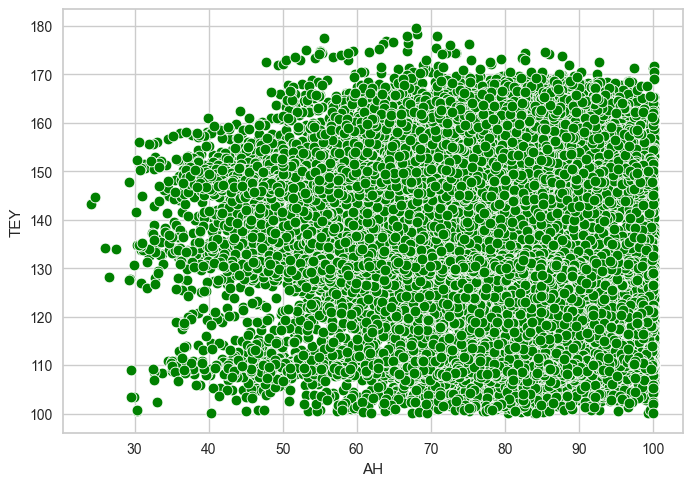

In [4]:
sns.scatterplot(x='AH', y='TEY', 
                data=df, s=60, color='green')
plt.savefig('scatterplot.png', dpi=100)

In [5]:
X = df[['AT', 'TEY']].values
X

array([[  4.5878, 134.67  ],
       [  4.2932, 134.67  ],
       [  3.9045, 135.1   ],
       ...,
       [  5.482 , 107.81  ],
       [  5.8837, 131.41  ],
       [  6.0392, 125.41  ]])

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(X)
X

array([[-1.76236198,  0.07450154],
       [-1.80191968,  0.07450154],
       [-1.85411274,  0.10203313],
       ...,
       [-1.64229242, -1.64526249],
       [-1.58835377, -0.13422633],
       [-1.56747386, -0.51838807]])

### Training the Model


In [7]:
model = KMeans(n_clusters=3, random_state=42)
model.fit(X)


KMeans(n_clusters=3, random_state=42)

### Plotting the Clusters


In [8]:
centroids = model.cluster_centers_
centroids

array([[ 0.97193867,  0.04044939],
       [-0.63445512, -0.61375032],
       [-0.78573464,  1.57996465]])

In [9]:
centroids = scaler.inverse_transform(centroids)


In [10]:
model.labels_

array([1, 1, 1, ..., 1, 1, 1], dtype=int32)

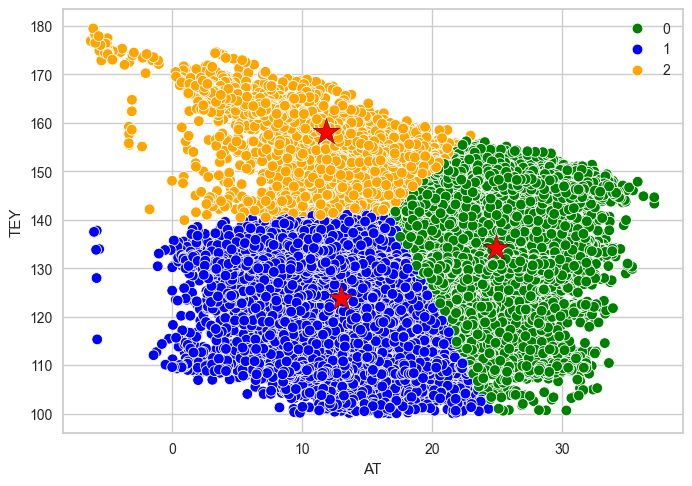

In [11]:
# Scatter plot of the data points
sns.scatterplot(x='AT', y='TEY', data=df, s=60, hue=model.labels_, palette=['green', 'blue', 'orange'])

# Scatter plot of the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], marker='*', s=400, color='red', edgecolor='black')

# Save the figure
plt.savefig('clustering.png', dpi=100)


### EVALUATION: Elbow Method


In [12]:
model.inertia_

28815.425175767727

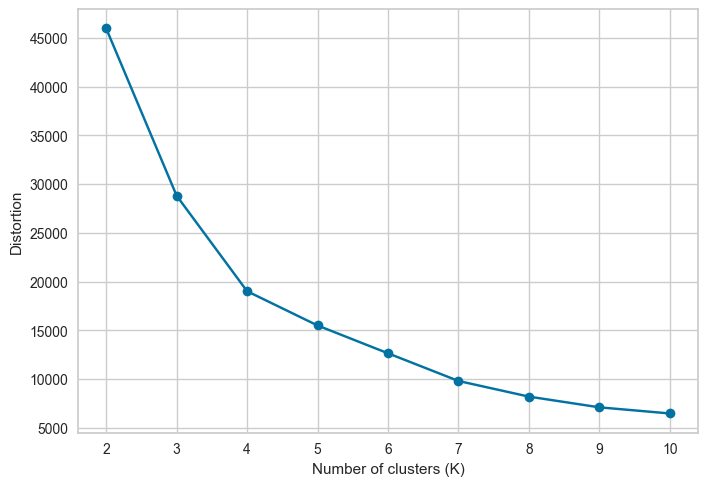

In [13]:
distortions = []

for k in range(2, 11):
    KMeans_model = KMeans(n_clusters=k, random_state=42)
    KMeans_model.fit(X)
    distortions.append(KMeans_model.inertia_)

plt.plot(range(2, 11), distortions,  marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Distortion')
plt.savefig('elbow plot.png')

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

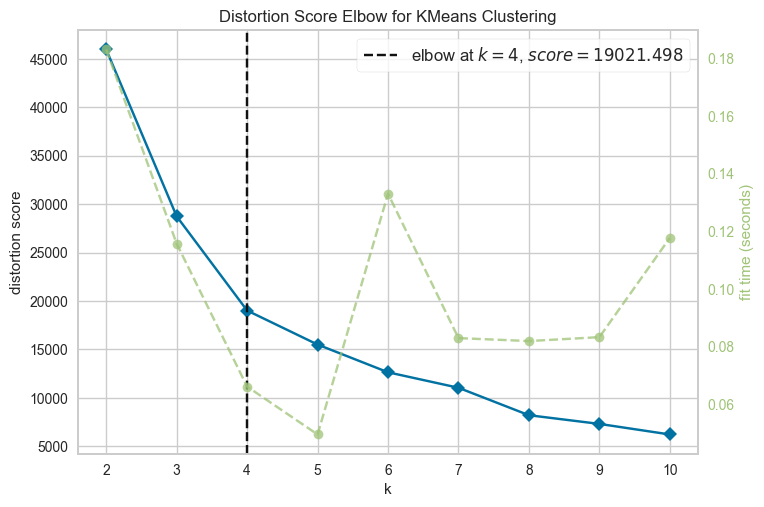

In [14]:
visualizer3 = KElbowVisualizer(KMeans(), k=(2,11))

visualizer3.fit(X) # Fit the data to the visualizer
visualizer3.show(outpath='elbowplot2.png')

### EVALUATION: Silhouette Score

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    model2 = KMeans(n_clusters=k, random_state=42)
    model2.fit(X)
    score = silhouette_score(X, model2.labels_)
    print("Silhouette Score for k = ", k, "is", score)
    silhouette_scores.append(score)

Text(0, 0.5, 'Silhouette score')

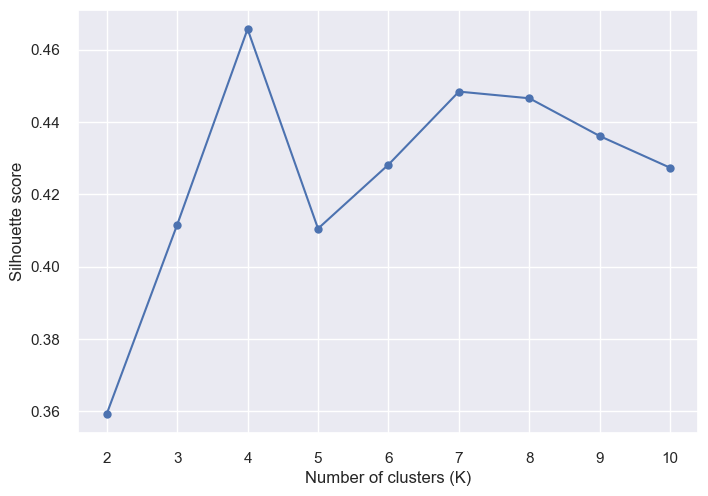

In [ ]:
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')

## FINAL CLUSTERS

### Training the Model


In [ ]:
model = KMeans(n_clusters=4, random_state=42)
model.fit(X)


KMeans(n_clusters=4, random_state=42)

### Plotting the Clusters


In [ ]:
centroids = model.cluster_centers_
centroids

array([[ 0.127401  , -1.41561745],
       [-0.87803036, -0.1668491 ],
       [-0.83422219,  1.63430974],
       [ 0.95888317,  0.25368326]])

In [ ]:
centroids = scaler.inverse_transform(centroids)


In [ ]:
model.labels_

array([1, 1, 1, ..., 1, 1, 1], dtype=int32)

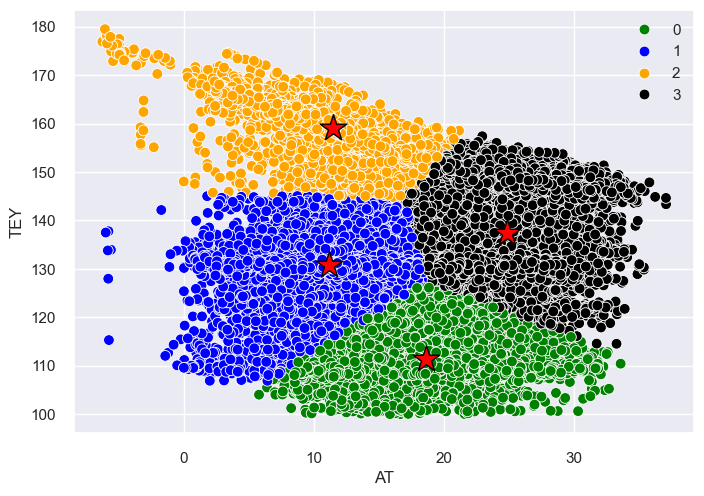

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot of the data points
sns.scatterplot(x='AT', y='TEY', data=df, s=60, hue=model.labels_, palette=['green', 'blue', 'orange', 'black'])

# Scatter plot of the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], marker='*', s=400, color='red', edgecolor='black')

# Save the figure
plt.savefig('clustering.png', dpi=100)
